In [1]:
import os, json, random, pathlib, zipfile
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (180, 180)
BATCH_SIZE = 32

os.makedirs("models", exist_ok=True)
os.makedirs("reports/figures", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset: selección y descripción



In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file(origin=URL, extract=True)
data_dir = pathlib.Path(archive).with_suffix("")
if not data_dir.exists():
    data_dir = next(pathlib.Path(archive).parent.rglob("flower_photos"))

paths = sorted(data_dir.glob("*/*.jpg"))      # todas las fotos
labels = [p.parent.name for p in paths]       # la carpeta es la clase
class_names = sorted(set(labels))             # ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
y = np.array([class_names.index(l) for l in labels])
num_classes = len(class_names)

print("Carpeta del dataset:", data_dir)
print("Total de imágenes:", len(paths))
print("Clases:", class_names)
for name, n in sorted(Counter(labels).items()):
    print(f"  {name:<12} {n} imágenes")

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Carpeta del dataset: /root/.keras/datasets/flower_photos.tgz/flower_photos
Total de imágenes: 3670
Clases: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
  daisy        633 imágenes
  dandelion    898 imágenes
  roses        641 imágenes
  sunflowers   699 imágenes
  tulips       799 imágenes


## 3. Exploración y visualización


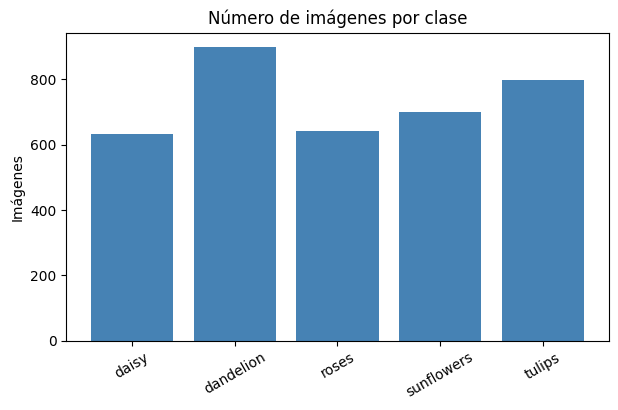

In [3]:
counts = Counter(labels)
plt.figure(figsize=(7, 4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.title("Número de imágenes por clase")
plt.ylabel("Imágenes")
plt.xticks(rotation=30)
plt.savefig("reports/figures/distribucion_clases.png", bbox_inches="tight", dpi=150)
plt.show()

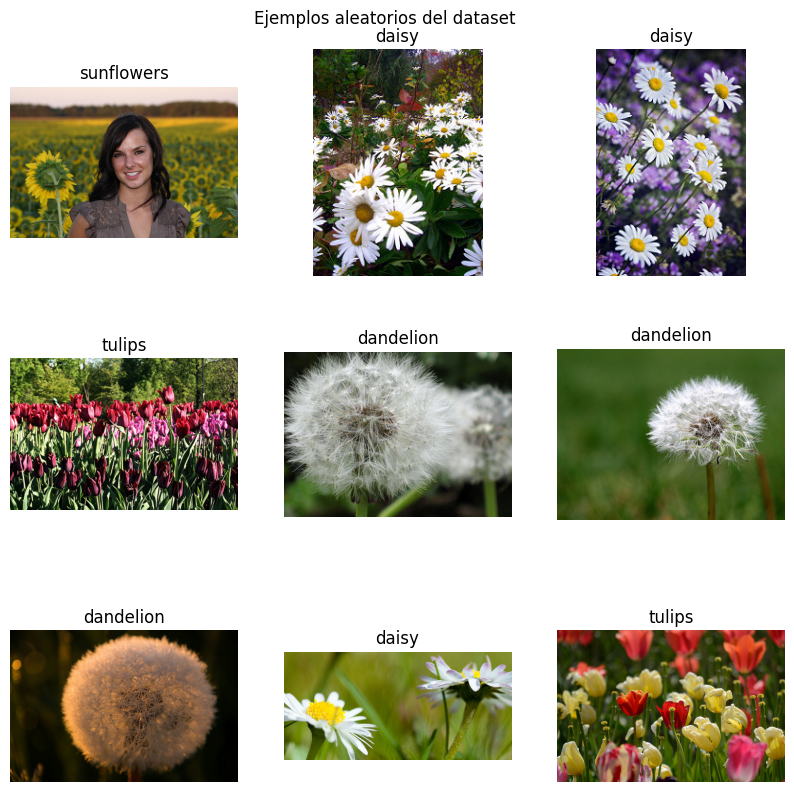

In [4]:
plt.figure(figsize=(10, 10))
for i, p in enumerate(random.sample(paths, 9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(Image.open(p))
    plt.title(p.parent.name)
    plt.axis("off")
plt.suptitle("Ejemplos aleatorios del dataset", y=0.92)
plt.savefig("reports/figures/ejemplos_dataset.png", bbox_inches="tight", dpi=150)
plt.show()

In [5]:
# Tamaños originales (revisamos una muestra de 300 fotos)
sizes = [Image.open(p).size for p in random.sample(paths, 300)]
widths, heights = zip(*sizes)
print(f"Ancho: mínimo {min(widths)}px, máximo {max(widths)}px")
print(f"Alto:  mínimo {min(heights)}px, máximo {max(heights)}px")
print(f"Combinaciones de tamaño distintas en la muestra: {len(set(sizes))}")

Ancho: mínimo 158px, máximo 500px
Alto:  mínimo 192px, máximo 441px
Combinaciones de tamaño distintas en la muestra: 81


## 4. División en entrenamiento, validación y prueba


In [6]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    paths, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Prueba: {len(X_test)}")
print()
print(f"{'clase':<12}{'train':>7}{'val':>7}{'test':>7}")
for i, name in enumerate(class_names):
    print(f"{name:<12}{(y_train == i).sum():>7}{(y_val == i).sum():>7}{(y_test == i).sum():>7}")

Entrenamiento: 2569 | Validación: 550 | Prueba: 551

clase         train    val   test
daisy           443     95     95
dandelion       629    134    135
roses           449     96     96
sunflowers      489    105    105
tulips          559    120    120


## 5. Preprocesamiento y normalización


In [7]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_dataset(paths_list, labels_arr, training=False):
    ds = tf.data.Dataset.from_tensor_slices(([str(p) for p in paths_list], labels_arr))
    if training:
        ds = ds.shuffle(len(paths_list), seed=SEED)   # mezcla el orden en cada época
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

images, lbls = next(iter(train_ds))
print("Forma de un lote de imágenes:", images.shape)   # (32, 180, 180, 3)
print("Rango de píxeles:", float(images.numpy().min()), "a", float(images.numpy().max()),
      "-> la capa Rescaling dentro del modelo los llevará a 0-1")

Forma de un lote de imágenes: (32, 180, 180, 3)
Rango de píxeles: 0.0 a 255.0 -> la capa Rescaling dentro del modelo los llevará a 0-1


## 6. Data Augmentation


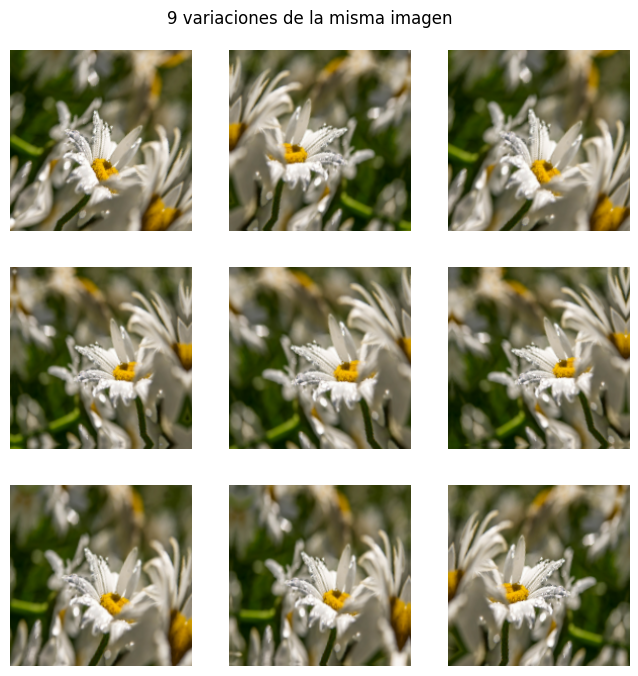

In [8]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ], name="data_augmentation")

# Visualizamos 9 variaciones de UNA misma imagen
aug_demo = make_augmentation()
sample = images[:1]
plt.figure(figsize=(8, 8))
for i in range(9):
    aug = aug_demo(sample, training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(aug[0].numpy().astype("uint8"))
    plt.axis("off")
plt.suptitle("9 variaciones de la misma imagen", y=0.93)
plt.savefig("reports/figures/ejemplos_augmentation.png", bbox_inches="tight", dpi=150)
plt.show()

## 7. Construcción y entrenamiento de la CNN



In [9]:
def build_model(num_classes, use_augmentation):
    model_layers = [keras.Input(shape=(*IMG_SIZE, 3))]
    if use_augmentation:
        model_layers.append(make_augmentation())
    model_layers += [
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ]
    model = keras.Sequential(model_layers)
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def train(model, epochs):
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True)
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[early_stop])

model_base = build_model(num_classes, use_augmentation=False)
model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Experimento A: CNN **sin** Data Augmentation (línea base)

In [10]:
hist_base = train(model_base, epochs=20)

Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 144ms/step - accuracy: 0.3994 - loss: 1.3978 - val_accuracy: 0.5436 - val_loss: 1.1302
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.5722 - loss: 1.0593 - val_accuracy: 0.5800 - val_loss: 1.0460
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.6555 - loss: 0.8904 - val_accuracy: 0.6073 - val_loss: 1.0009
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.7322 - loss: 0.7076 - val_accuracy: 0.6509 - val_loss: 0.9205
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.8026 - loss: 0.5174 - val_accuracy: 0.6473 - val_loss: 0.9717
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.8665 - loss: 0.3788 - val_accuracy: 0.6127 - val_loss: 1.1402
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9105 - loss: 0.2546 - val_accuracy: 0.6636 - val_loss: 1.1027
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9576 - loss: 0.1450 - val_accuracy: 0.6418 -

### 7.2 Experimento B: CNN **con** Data Augmentation

In [11]:
model_aug = build_model(num_classes, use_augmentation=True)
hist_aug = train(model_aug, epochs=40)

Epoch 1/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.3939 - loss: 1.4529 - val_accuracy: 0.5364 - val_loss: 1.1217
Epoch 2/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.5640 - loss: 1.0653 - val_accuracy: 0.5309 - val_loss: 1.2368
Epoch 3/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.6123 - loss: 0.9609 - val_accuracy: 0.6073 - val_loss: 0.9974
Epoch 4/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 10s 64ms/step - accuracy: 0.6442 - loss: 0.8956 - val_accuracy: 0.6491 - val_loss: 1.0503
Epoch 5/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.6715 - loss: 0.8375 - val_accuracy: 0.6200 - val_loss: 1.1603
Epoch 6/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.6975 - loss: 0.7733 - val_accuracy: 0.6727 - val_loss: 0.8671
Epoch 7/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.7178 - loss: 0.7420 - val_accuracy: 0.6927 - val_loss: 0.9245
Epoch 8/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.7127 - loss: 0.7393 - val_accuracy: 0.6382 -

## 8. Gráficas del entrenamiento


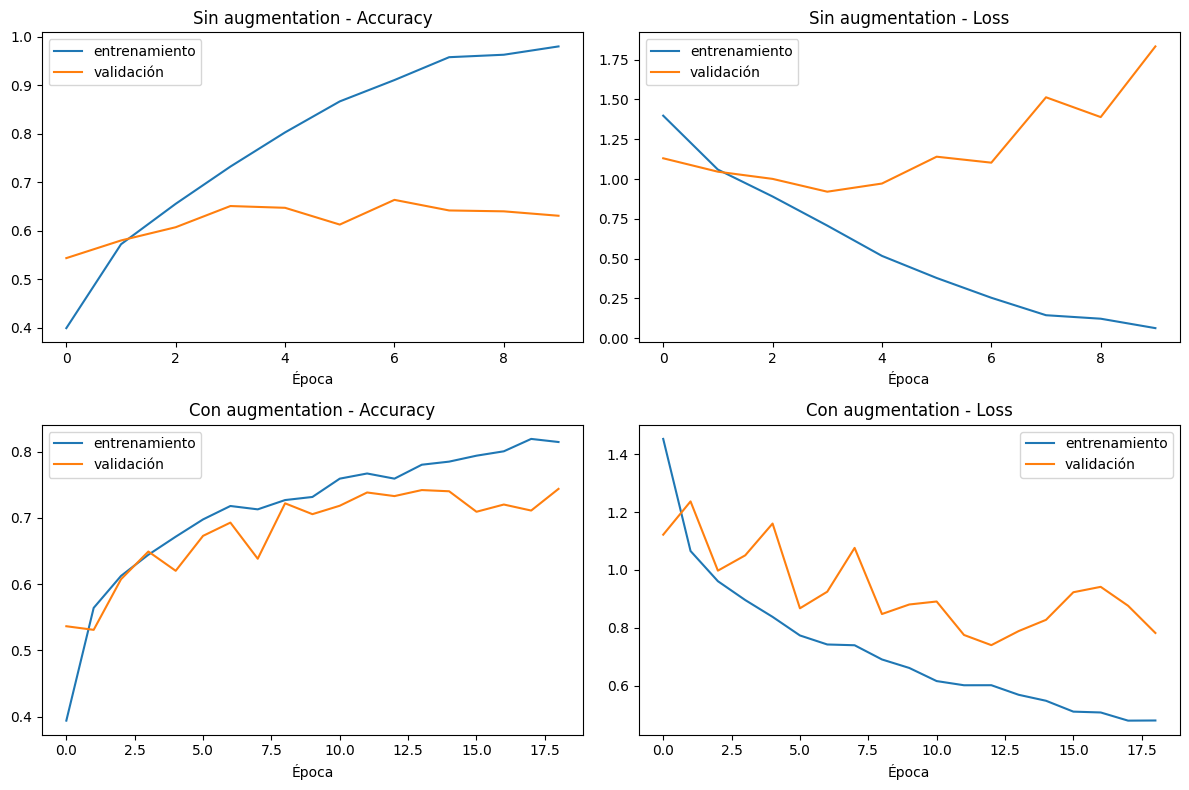

Mejor val_accuracy SIN augmentation: 66.36%
Mejor val_accuracy CON augmentation: 74.36%


In [12]:
def plot_history(h, title, axes):
    axes[0].plot(h.history["accuracy"], label="entrenamiento")
    axes[0].plot(h.history["val_accuracy"], label="validación")
    axes[0].set_title(f"{title} - Accuracy"); axes[0].set_xlabel("Época"); axes[0].legend()
    axes[1].plot(h.history["loss"], label="entrenamiento")
    axes[1].plot(h.history["val_loss"], label="validación")
    axes[1].set_title(f"{title} - Loss"); axes[1].set_xlabel("Época"); axes[1].legend()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_history(hist_base, "Sin augmentation", axes[0])
plot_history(hist_aug, "Con augmentation", axes[1])
plt.tight_layout()
plt.savefig("reports/figures/curvas_entrenamiento.png", dpi=150)
plt.show()

print(f"Mejor val_accuracy SIN augmentation: {max(hist_base.history['val_accuracy']):.2%}")
print(f"Mejor val_accuracy CON augmentation: {max(hist_aug.history['val_accuracy']):.2%}")

## 9. Evaluación y matriz de confusión


In [13]:

final_model = model_aug

for name, m in [("Sin augmentation", model_base), ("Con augmentation", model_aug)]:
    loss, acc = m.evaluate(test_ds, verbose=0)
    print(f"{name}: test loss = {loss:.4f} | test accuracy = {acc:.2%}")

y_prob = final_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.array(y_test)

print("\nReporte de clasificación (modelo final):\n")
print(classification_report(y_true, y_pred, target_names=class_names))

Sin augmentation: test loss = 0.8868 | test accuracy = 68.06%
Con augmentation: test loss = 0.7643 | test accuracy = 68.97%

Reporte de clasificación (modelo final):

              precision    recall  f1-score   support

       daisy       0.69      0.62      0.66        95
   dandelion       0.77      0.78      0.77       135
       roses       0.63      0.45      0.52        96
  sunflowers       0.77      0.84      0.80       105
      tulips       0.58      0.71      0.64       120

    accuracy                           0.69       551
   macro avg       0.69      0.68      0.68       551
weighted avg       0.69      0.69      0.69       551



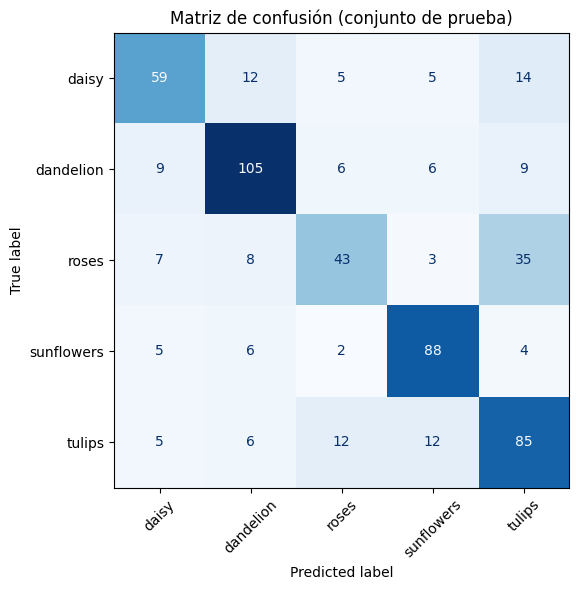

In [14]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (conjunto de prueba)")
plt.tight_layout()
plt.savefig("reports/figures/matriz_confusion.png", dpi=150)
plt.show()

## 10. Predicciones con imágenes


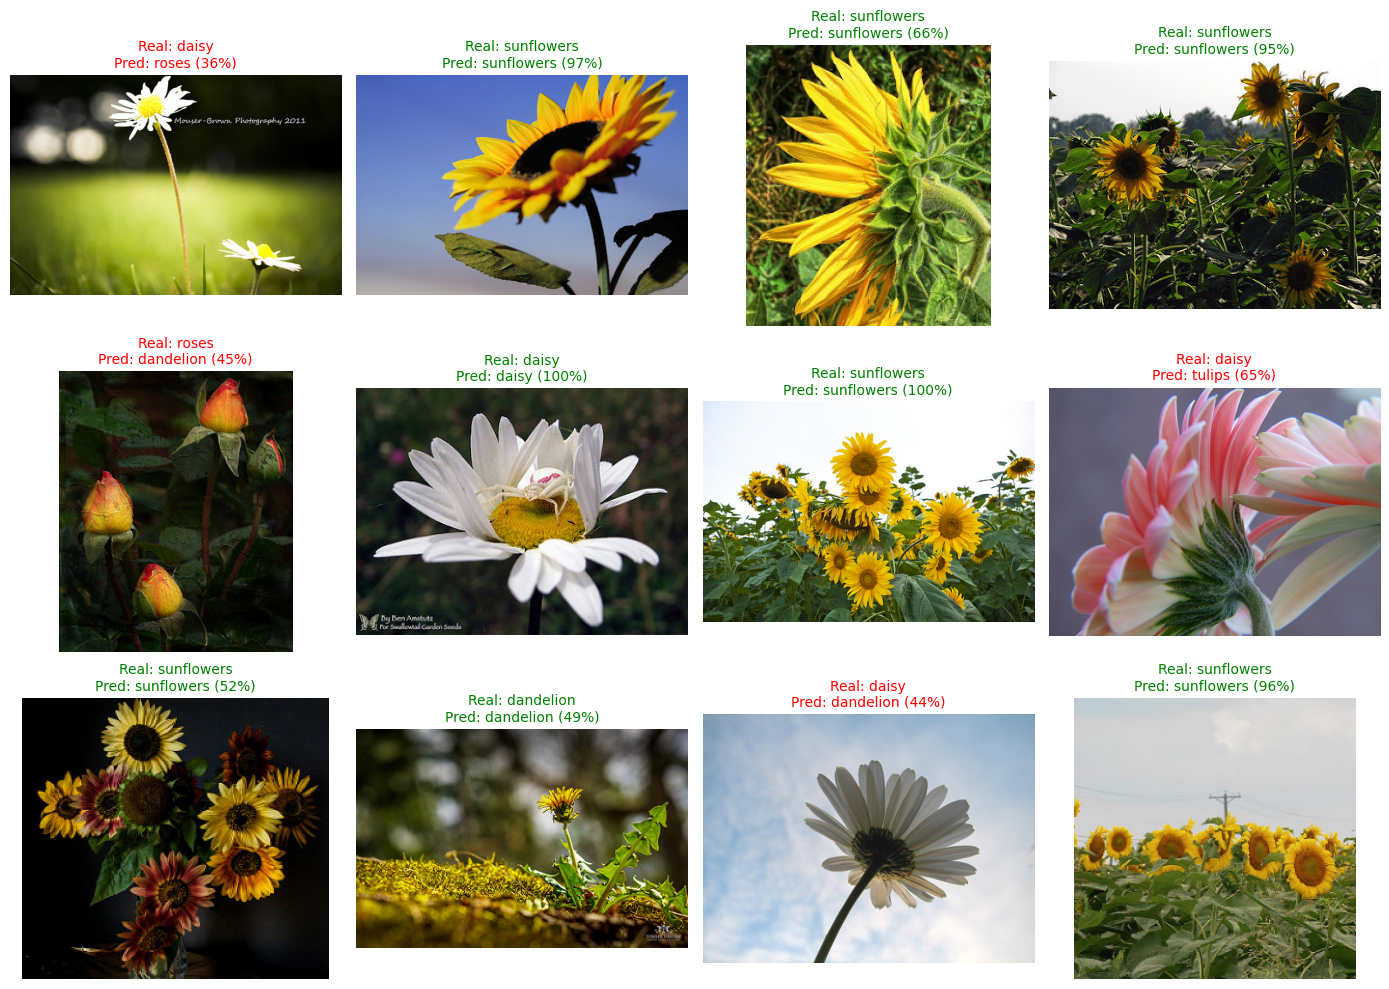

In [15]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_test), 12, replace=False)

plt.figure(figsize=(14, 10))
for k, i in enumerate(idx):
    plt.subplot(3, 4, k + 1)
    plt.imshow(Image.open(X_test[i]).convert("RGB"))
    plt.axis("off")
    ok = y_pred[i] == y_true[i]
    plt.title(f"Real: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({y_prob[i].max():.0%})",
              color="green" if ok else "red", fontsize=10)
plt.tight_layout()
plt.savefig("reports/figures/predicciones.png", dpi=150)
plt.show()

## 11. Guardado del modelo


In [16]:
final_model.save("models/flower_cnn.keras")
with open("models/class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f)

# Verificación: el modelo guardado debe dar las mismas predicciones
loaded = keras.models.load_model("models/flower_cnn.keras")
batch, _ = next(iter(test_ds))
same = np.allclose(final_model.predict(batch, verbose=0), loaded.predict(batch, verbose=0), atol=1e-5)
print("El modelo guardado da las mismas predicciones:", same)
print("Tamaño del modelo:", round(os.path.getsize("models/flower_cnn.keras") / 1e6, 1), "MB")

El modelo guardado da las mismas predicciones: True
Tamaño del modelo: 79.8 MB


In [17]:
# Empaquetar modelo + gráficas en un solo zip y descargarlo
with zipfile.ZipFile("resultados_colab.zip", "w") as z:
    for folder in ["models", "reports"]:
        for root, _, files_in in os.walk(folder):
            for fname in files_in:
                z.write(os.path.join(root, fname))

try:
    from google.colab import files
    files.download("resultados_colab.zip")
except ImportError:
    print("No estás en Colab: el zip quedó en la carpeta actual.")

# Versiones usadas (cópialas a requirements.txt si hace falta)
print("\nVersiones para requirements.txt:")
print(f"tensorflow=={tf.__version__}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Versiones para requirements.txt:
tensorflow==2.21.0
